In [39]:
import pandas as pd
import wget
import numpy as np

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [41]:
modulehw_url="https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
modulehw_data=wget.download(modulehw_url)

100% [............................................................................] 278746 / 278746

In [42]:
df=pd.read_csv(modulehw_data)

In [43]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [44]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [45]:
categorical = list(df.dtypes[df.dtypes == 'string'].index)

In [46]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [47]:
df[categorical] = df[categorical].fillna('NA')

In [48]:
df.isnull().sum()

lead_source                   0
industry                      0
employment_status             0
location                      0
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [49]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [50]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [51]:
df[numerical] = df[numerical].fillna(0)

In [52]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [53]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [54]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [55]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [56]:
auc = roc_auc_score(y_train, df_train['annual_income'])
auc

0.6081977776250831

In [57]:
auc = roc_auc_score(y_train, df_train['number_of_courses_viewed'])
auc

0.7229894623989618

In [58]:
auc = roc_auc_score(y_train, df_train['interaction_count'])
auc

0.7649203047563227

In [59]:
auc = roc_auc_score(y_train, df_train['lead_score'])
auc

0.7882254810906102

In [60]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [61]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [62]:
dv, model = train(df_train, y_train, C=1)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [63]:
y_pred = predict(df_val, dv, model)

In [64]:
def train2(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear',C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [65]:
dv, model = train2(df_train, y_train, C=1)

In [66]:
y_pred = predict(df_val, dv, model)
y_pred

array([0.54472295, 0.79005207, 0.50977909, 0.52913949, 0.82072027,
       0.54246   , 0.50178717, 0.54698398, 0.82553299, 0.40583754,
       0.91301567, 0.33581825, 0.30789883, 0.42704803, 0.6219229 ,
       0.53665458, 0.41931937, 0.84087345, 0.79969125, 0.61790114,
       0.61625181, 0.68059931, 0.85605897, 0.8078487 , 0.62046017,
       0.45970722, 0.54556724, 0.41221393, 0.72714023, 0.46812079,
       0.77222191, 0.79043883, 0.61433884, 0.78549759, 0.49753426,
       0.66077291, 0.69804763, 0.76896543, 0.65657501, 0.64127911,
       0.66509115, 0.57942826, 0.67830946, 0.61186114, 0.86890227,
       0.4146967 , 0.84130129, 0.74229365, 0.68028539, 0.7189143 ,
       0.86417929, 0.64043375, 0.5424699 , 0.70225152, 0.27894903,
       0.70826494, 0.62310718, 0.47781771, 0.37914032, 0.69936035,
       0.52032869, 0.69977698, 0.75148939, 0.58087503, 0.47001802,
       0.56863492, 0.91297185, 0.79972028, 0.82206546, 0.36140197,
       0.66132404, 0.52330065, 0.79295471, 0.72068083, 0.71234

In [67]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

In [68]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))
    
    if t == 0.21:
        print ('0.21:',2*((tp/(tp+fp))*(tp/(tp+fn)))/((tp/(tp+fp))+(tp/(tp+fn))))
    if t == 0.41000000000000003:
        print ('0.41:',2*((tp/(tp+fp))*(tp/(tp+fn)))/((tp/(tp+fp))+(tp/(tp+fn))))
    if t == 0.61:
        print ('0.61:',2*((tp/(tp+fp))*(tp/(tp+fn)))/((tp/(tp+fp))+(tp/(tp+fn))))
    if t == 0.81:
        print ('0.81:',2*((tp/(tp+fp))*(tp/(tp+fn)))/((tp/(tp+fp))+(tp/(tp+fn))))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
df_scores['prc'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['f1'] = 2*((df_scores.tp / (df_scores.tp + df_scores.fp))*(df_scores.tp / (df_scores.tp + df_scores.fn))) / (df_scores.tp / (df_scores.tp + df_scores.fp)+df_scores.tp / (df_scores.tp + df_scores.fn))

0.21: 0.7389659520807063
0.41: 0.7576158940397352
0.61: 0.7450657894736842
0.81: 0.3397260273972603


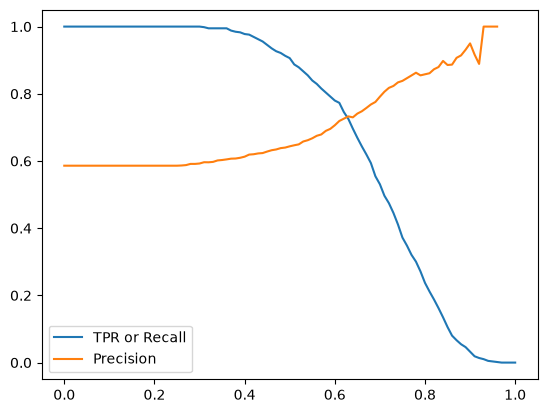

In [69]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR or Recall')
plt.plot(df_scores.threshold, df_scores['prc'], label='Precision')
plt.legend()

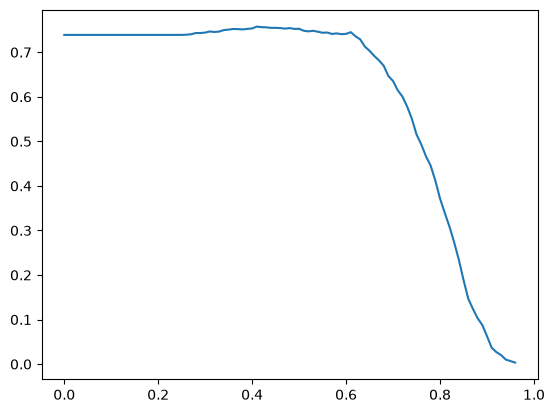

In [70]:
plt.plot(df_scores.threshold, df_scores['f1'], label='F1 score')

In [71]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [72]:
from tqdm.auto import tqdm

n_splits = 5

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train2(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1 0.732 +- 0.007


In [73]:
def train3(df_train, y_train, C=C):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear',C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [74]:
for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train3(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
